# RF 07 — Random Forest Experimental Summary and Conclusions

This notebook consolidates the findings of the independent Random Forest phishing-email detection experiment. It brings together the locked baseline, SHAP-based error analysis, counterfactual discovery, controlled synthetic-email validation, and final weighted-retraining evaluation. The aim is to present the experimental evidence in one place without repeating the training procedures documented in RF 00–RF 06.

The central objective was to **reduce false-positive phishing alerts without increasing false negatives**. The recorded intervention reduced false positives from **62 to 57** while maintaining **15 false negatives**.

This notebook contains a concise record of the results and reproducible summary visualizations. The original model-building and validation code remains in the preceding notebooks.


## 1. Experimental design and dataset

The Random Forest experiment was evaluated independently of the other classifiers in the thesis. The original phishing-email dataset was conservatively cleaned, split into training and test partitions, and transformed using a fixed TF-IDF representation.

**Table 1. Dataset and experimental configuration**

| Component | Recorded specification |
|:---|:---|
| Dataset | Nazario_5 and TREC07 phishing email dataset |
| Cleaned email records | 53,577 |
| Legitimate emails | 23,739 (44.31%) |
| Phishing emails | 29,838 (55.69%) |
| Training partition | 42,861 emails (80%) |
| Test partition | 10,716 emails (20%) |
| Data partitioning | Stratified; random state = 42 |
| TF-IDF vocabulary | Maximum 10,000 features |
| TF-IDF n-grams | Unigrams and bigrams |
| TF-IDF document-frequency filters | `min_df=2`; `max_df=0.95` |
| Classifier | Random Forest, 100 trees |
| Model random state | 42 |
| Primary improvement condition | Final FP < 62; final FN ≤ 15 |

The original train/test split, fitted vocabulary, and classifier settings were retained for the intervention analysis.


## 2. Locked Random Forest baseline

The baseline established the original classification performance before any counterfactual-guided intervention.

**Table 2. Locked baseline performance**

| Performance measure | Recorded value |
|:---|---:|
| Accuracy | 0.99281448 |
| Precision (phishing class) | 0.98969244 |
| Recall (phishing class) | 0.99748660 |
| F1-score (phishing class) | 0.99357423 |
| ROC-AUC | 0.99911353 |
| False positives | 62 |
| False negatives | 15 |

The baseline already achieved strong overall performance. The experiment therefore focused on a more specific practical issue: legitimate emails incorrectly flagged as phishing.


## 3. SHAP analysis of classification errors

SHAP explanations were calculated for all **62 baseline false positives** and **15 baseline false negatives**. The analysis examined feature contributions to the phishing-class probability and provided a basis for selecting candidate features for intervention.

**Table 3. Highest-ranked false-positive SHAP features**

| Feature | Mean absolute SHAP contribution |
|:---|---:|
| `wrote` | 0.02765090 |
| `org` | 0.02296829 |
| `code` | 0.02025850 |
| `escapenumber escapenumber` | 0.01361738 |
| `perl` | 0.00970759 |

These are the highest-ranked features in the recorded false-positive explanation summary. Their importance identifies influential model features; it does not, by itself, establish that removing any one feature from an email would safely correct a prediction.


## 4. Feature intervention and counterfactual discovery

The SHAP-guided screening identified **507 candidate features** that were active in at least one false positive, absent from all 15 false negatives, and associated with positive phishing-class SHAP contributions.

An initial feature-dropout experiment did not satisfy the joint error-reduction condition. A subsequent case-specific, greedy feature-masking search produced **nine verified counterfactuals** from the 62 baseline false-positive cases. Minimality was verified within the selected greedy search procedure, not across every possible feature subset.

**Table 4. Feature-dropout experiment**

| Feature-dropout rate | False positives | False negatives | Meets joint target? |
|---:|---:|---:|:---:|
| 0% (baseline) | 62 | 15 | No |
| 10% | 65 | 13 | No |
| 25% | 63 | 15 | No |
| 50% | 68 | 17 | No |
| 75% | 71 | 14 | No |

**Table 5. Counterfactual discovery summary**

| Measure | Recorded outcome |
|:---|---:|
| False-positive cases examined | 62 |
| Verified counterfactual cases | 9 |
| Cases without verified counterfactuals | 53 |
| Verification success rate | 14.52% |
| Counterfactual feature occurrences | 41 |
| Distinct counterfactual features | 40 |
| Mean selected features per verified case | 4.56 |
| Median selected features per verified case | 3 |

The feature-dropout result was retained as a negative finding. The nine verified counterfactuals supplied the case-specific evidence used in the later text-based intervention.


## 5. Counterfactual-guided synthetic email validation

The original email texts were recovered and matched to the locked TF-IDF representation. The nine verified counterfactual cases were then examined in their original textual context. The subsequent generation procedure produced closely related legitimate-email variants while preserving the selected counterfactual features and applying controlled text changes.

**Table 6. Synthetic-email generation and validation**

| Validation measure | Recorded result |
|:---|---:|
| Synthetic legitimate-email candidates | 9 |
| Approved candidates | 9 |
| Rejected candidates | 0 |
| Candidates preserving selected counterfactual features | 9 |
| Minimum required TF-IDF cosine similarity | 0.98 |
| Mean recorded TF-IDF cosine similarity | 0.99691915 |
| Candidates still classified as phishing by the baseline | 9 |

The nine approved variants were incorporated into the final training intervention with a selected sample weight of **7** per synthetic example. The original training examples retained weight **1**, and the original TF-IDF vocabulary and Random Forest settings were preserved.


## 6. Final evaluation and comparison

**Table 7. Baseline versus final classification outcomes**

| Actual label and predicted outcome | Baseline RF | Final RF | Change |
|:---|---:|---:|---:|
| Legitimate correctly classified as legitimate | 4,686 | 4,691 | +5 |
| Legitimate incorrectly classified as phishing (FP) | 62 | 57 | −5 |
| Phishing incorrectly classified as legitimate (FN) | 15 | 15 | 0 |
| Phishing correctly classified as phishing | 5,953 | 5,953 | 0 |
| **Total evaluated emails** | **10,716** | **10,716** | **0** |

**Table 8. Primary intervention outcome**

| Outcome | Recorded value |
|:---|---:|
| Baseline false positives | 62 |
| Final false positives | 57 |
| Absolute false-positive reduction | 5 |
| Relative false-positive reduction | 8.06% |
| Baseline false negatives | 15 |
| Final false negatives | 15 |
| Joint improvement condition satisfied | Yes |

The final model corrected five additional legitimate emails without introducing additional false negatives in the recorded evaluation.


### Figure 1. Final Random Forest confusion matrix

The final model correctly classified 4,691 legitimate emails and 5,953 phishing emails, with 57 false positives and 15 false negatives. Rows indicate the actual class; columns indicate the predicted class.


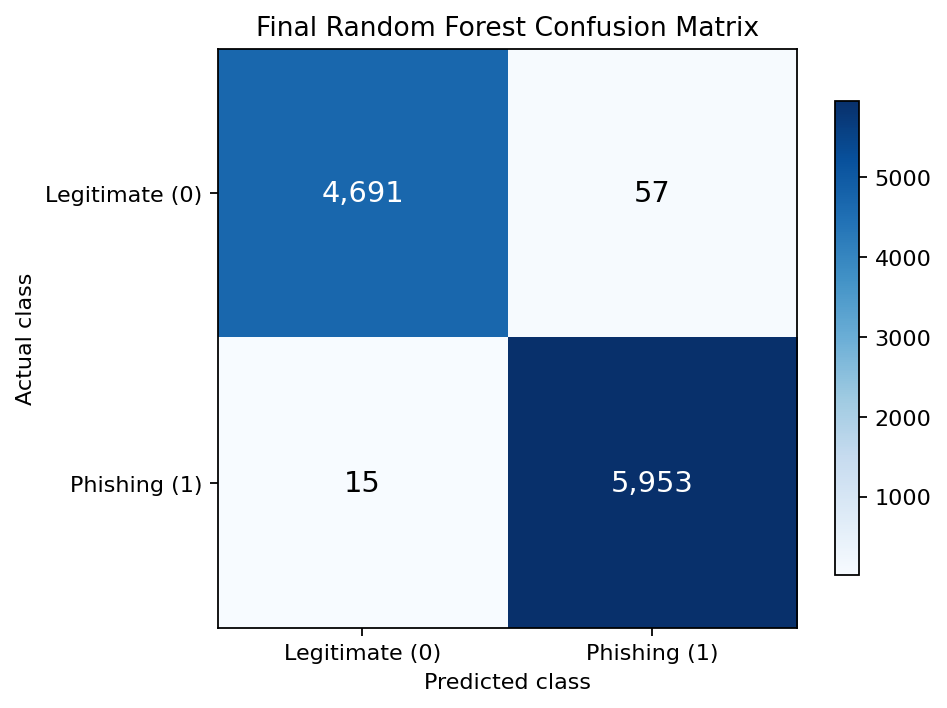

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

final_confusion_matrix = np.array([[4691, 57], [15, 5953]])
fig, ax = plt.subplots(figsize=(6.2, 4.7))
image = ax.imshow(final_confusion_matrix, cmap="Blues")
for (row, col), value in np.ndenumerate(final_confusion_matrix):
    ax.text(col, row, f"{value:,}", ha="center", va="center",
            fontsize=13, color="white" if value > 3000 else "black")
ax.set_xticks([0, 1], ["Legitimate (0)", "Phishing (1)"])
ax.set_yticks([0, 1], ["Legitimate (0)", "Phishing (1)"])
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
ax.set_title("Final Random Forest Confusion Matrix")
fig.colorbar(image, ax=ax, shrink=0.82)
plt.tight_layout()
plt.show()


### Figure 2. False-positive and false-negative comparison

The recorded intervention reduced false positives by five cases (8.06%), while false negatives remained unchanged. This directly addresses the experiment's predefined objective.


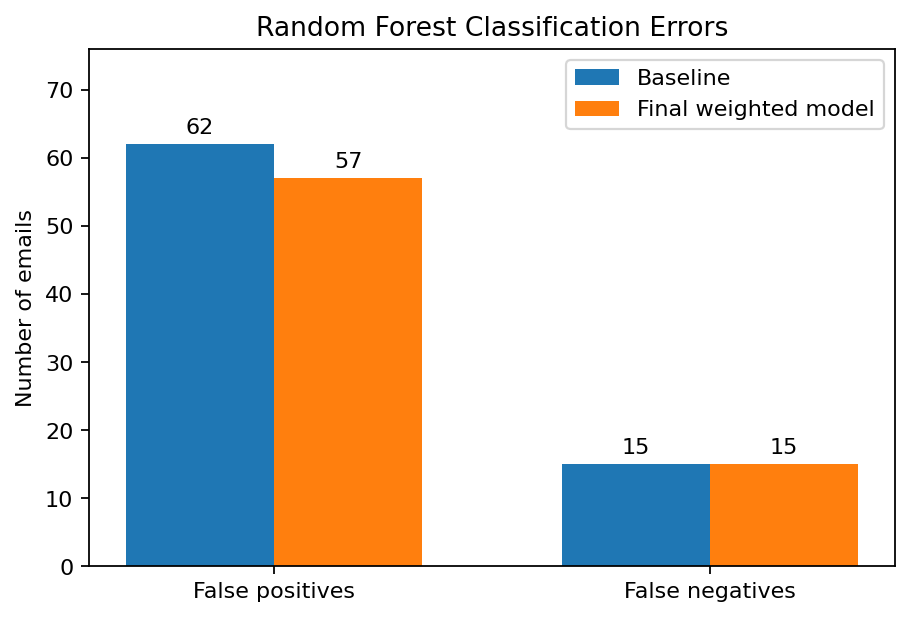

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

categories = ["False positives", "False negatives"]
baseline_errors = [62, 15]
final_errors = [57, 15]
positions = np.arange(len(categories))
width = 0.34

fig, ax = plt.subplots(figsize=(6.5, 4.2))
baseline_bars = ax.bar(positions - width / 2, baseline_errors, width, label="Baseline")
final_bars = ax.bar(positions + width / 2, final_errors, width, label="Final weighted model")
ax.bar_label(baseline_bars, padding=3)
ax.bar_label(final_bars, padding=3)
ax.set_xticks(positions, categories)
ax.set_ylim(0, 76)
ax.set_ylabel("Number of emails")
ax.set_title("Random Forest Classification Errors")
ax.legend()
plt.tight_layout()
plt.show()


### Figure 3. Leading false-positive SHAP features

The plot summarizes the five largest mean absolute SHAP contributions recorded for the baseline false-positive cases. The chart reports feature influence, not causal effects of editing those features.


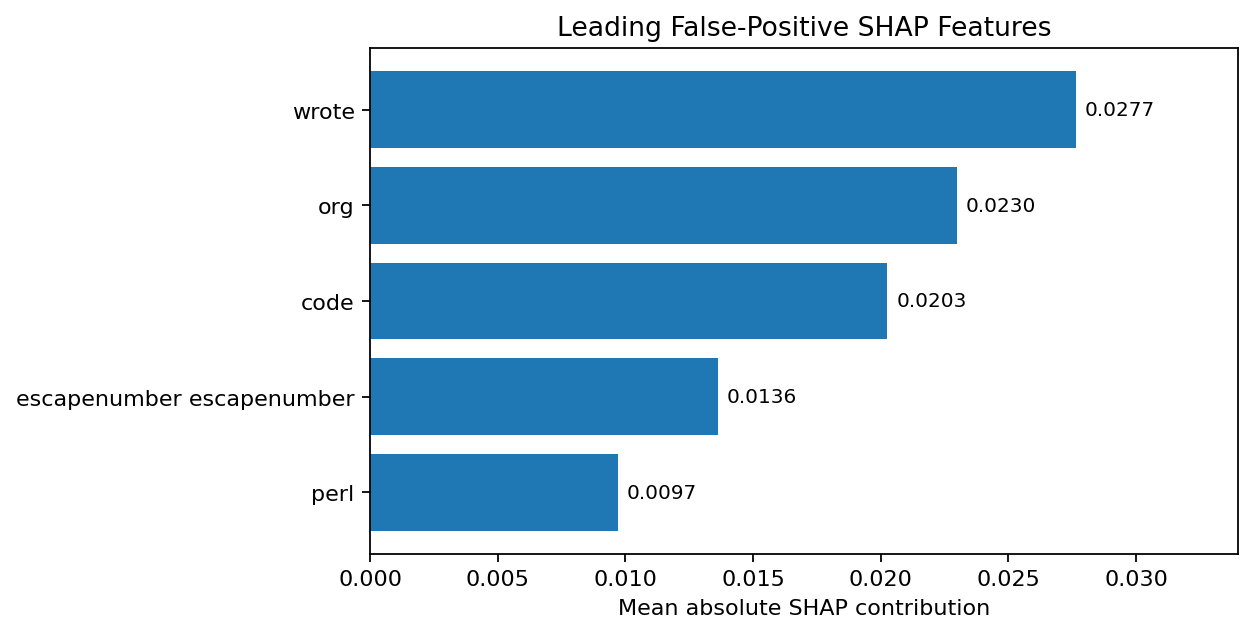

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

feature_names = ["wrote", "org", "code", "escapenumber escapenumber", "perl"]
mean_abs_shap = [0.02765090, 0.02296829, 0.02025850, 0.01361738, 0.00970759]
y_positions = np.arange(len(feature_names))
fig, ax = plt.subplots(figsize=(7, 4.1))
ax.barh(y_positions, mean_abs_shap)
ax.set_yticks(y_positions, feature_names)
ax.invert_yaxis()
ax.set_xlabel("Mean absolute SHAP contribution")
ax.set_title("Leading False-Positive SHAP Features")
for i, value in enumerate(mean_abs_shap):
    ax.text(value + 0.00035, i, f"{value:.4f}", va="center", fontsize=9)
ax.set_xlim(0, 0.034)
plt.tight_layout()
plt.show()


## 7. Interpretation and conclusions

The independent Random Forest experiment began with a strong baseline but identified 62 legitimate emails incorrectly classified as phishing. SHAP explanations provided feature-level evidence for those errors, and the feature-dropout experiment showed that broad feature removal did not meet the desired error balance.

Case-specific counterfactual analysis identified nine verified feature-space interventions. The original email texts were recovered and compared with their TF-IDF representations, and nine closely related legitimate-email candidates were generated and validated. The original training examples, labels, and TF-IDF feature representation were preserved during the subsequent weighted-retraining procedure.

The synthetic candidates were informed by the baseline's misclassified legitimate emails in the evaluation set. With the nine approved candidates assigned a sample weight of 7, the final Random Forest reduced false positives from **62 to 57 (8.06%)**, while false negatives remained at **15**. The recorded results therefore met the experiment's predefined objective.

Together, the SHAP analysis, verified counterfactuals, synthetic-email validation, and final evaluation demonstrate the outcome of the explainability-guided intervention within this Random Forest experiment. The detailed code and intermediate results for each stage are documented in RF 00–RF 06.
